# HW4: purged model comparison and trading strategy

**Henri Mertens**

Predict a stock's next-entry 90-calendar-day return, then use relative
forecasts to choose long positions. This notebook displays the saved
experiment; model fitting and accounting are implemented in the accompanying
Python files. See [README.md](README.md) for run instructions and sources.

The small Ridge exercise in `02_model_development.ipynb` was a classroom
pilot. The experiment below uses the full supplied homework universe.

The report can read the compact `results/` files in a fresh checkout.
Rebuilding the model and daily accounting is a separate workflow described
in the README; opening this report does not fit a model or start a backtest.


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

homework_directory = None
for parent in [Path.cwd(), *Path.cwd().parents]:
    for candidate in [
        parent,
        parent / 'Homeworks/HW4/henri_mertens',
        parent / ('Python for Financial Engineers/'
                  'UCB-MFE-python-preprogram-2026-winter/'
                  'Homeworks/HW4/henri_mertens'),
    ]:
        if (candidate / 'research_config.json').is_file():
            homework_directory = candidate
            break
    if homework_directory is not None:
        break
if homework_directory is None:
    raise FileNotFoundError('Open the notebook from the homework workspace.')

output_directory = homework_directory / 'outputs'
if not (output_directory / 'frozen_experiment.json').is_file():
    output_directory = homework_directory / 'results'
configuration = json.loads(
    (homework_directory / 'research_config.json').read_text()
)
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_colwidth', 70)


## Dates and information boundaries

Only pre-2016 features and completed outcomes are used for fitting.
Financial ratios are available from the recorded filing date plus one day.
The full database includes later-restated vendor financials, so recorded
timing cannot establish a perfectly historical point-in-time feed.

The inner windows tune parameters on 2012 and 2013. Every validation date
holds out all stocks together. A training row is removed if its actual
return-label endpoint reaches the next validation window, with a further
five-session gap. The training window expands over time. Since no training
observations follow validation, a post-validation embargo is unnecessary.

The six tuned families are compared on 2014. The selected family is checked
on 2015 without selecting a replacement or changing the strategy. Only
outcomes known by each selection cutoff are scored. The 2016 buffer is not
used for training. The final test is April 1, 2016–September 30, 2026 with
frozen preprocessing and model coefficients.


In [2]:
split_audit = pd.read_csv(output_directory / 'split_audit.csv')
display(split_audit)
for split in split_audit.itertuples():
    assert pd.Timestamp(split.last_training_outcome) < pd.Timestamp(
        split.purge_boundary
    ) <= pd.Timestamp(split.first_validation_signal)

calendar_days = (
    pd.Timestamp(configuration['test_end'])
    - pd.Timestamp(configuration['test_start'])
).days
display(Markdown(
    f'The final test spans **{calendar_days:,} elapsed calendar days** '
    f'(**{calendar_days + 1:,} dates** counting both endpoints).'
))


,fold,first_validation_signal,purge_boundary,last_training_signal,last_training_outcome,training_rows_available,training_rows_used,validation_rows
0,inner_2012,2012-01-31 00:00:00,2012-01-24 00:00:00,2011-09-30 00:00:00,2012-01-03 00:00:00,40364,6000,23714
1,inner_2013,2013-01-31 00:00:00,2013-01-24 00:00:00,2012-09-28 00:00:00,2012-12-31 00:00:00,64065,6000,23809
2,selection_2014,2014-01-31 00:00:00,2014-01-24 00:00:00,2013-09-30 00:00:00,2013-12-30 00:00:00,87853,6000,23853


The final test spans **3,834 elapsed calendar days** (**3,835 dates** counting both endpoints).

## Training-only feature selection

The 12 candidate inputs are the five lecture price features, six financial
ratios and filing age. Current active status, future prices, label endpoints
and static sector classifications are excluded from the predictor list.

Each fold uses the same seeded, date-balanced sample of at most 6,000
training rows for all six models. This bounds laptop compute, especially
for the RBF support-vector model. Validation retains all eligible names.
Clipping, imputation, scaling, target standardization and Boruta are learned
inside the training window, never on pooled training/validation data.

Boruta compares a forest's feature importance with shuffled shadow inputs.
Only confirmed inputs are used; tentative inputs are shown separately.
If none are confirmed, predict the training mean. Training return tails are
clipped using training-only 1st/99th percentiles. Validation errors use the
unmodified outcomes. Overlapping labels and correlated stocks mean Boruta's
decisions should not be read as independent statistical proofs.


In [3]:
feature_tables = []
for feature_file in sorted(output_directory.glob('features_*.csv')):
    table = pd.read_csv(feature_file)
    table['training_window'] = feature_file.stem.removeprefix('features_')
    feature_tables.append(table)
feature_selection = pd.concat(feature_tables, ignore_index=True)
display(feature_selection.pivot(
    index='feature', columns='training_window', values='confirmed'
))


training_window,confirmation_2015,final_pre2016,inner_2012,inner_2013,selection_2014
feature,,,,,
accruals_to_assets,False,False,False,False,False
cash_to_assets,False,True,False,False,False
debt_to_assets,False,False,True,True,True
drawdown_252,True,True,True,True,True
fcf_to_assets,False,False,True,False,False
filing_age_days,True,True,True,True,True
momentum_21,True,True,True,True,True
momentum_252_21,True,True,True,True,True
momentum_63,True,True,True,True,True


## Hyperparameters and model-family selection

Elastic Net, XGBoost, CatBoost, an MLP, Kalman regression and RBF SVR each
receive 12 Optuna TPE trials, including four initial random trials. Search
ranges are fixed in the README and code. No early-stopping set is randomly
drawn from later dates. The Kalman filter updates coefficients by monthly
training cross-section and leaves its state unchanged during prediction.

The search maximizes average monthly Spearman rank correlation: does a
higher prediction tend to accompany a higher realized return among stocks
on the same date? This aligns with the portfolio's ranking rule. The 2014
comparison selects the winner by the same measure, with RMSE breaking ties.
An intercept-only forecast has no cross-sectional ranking and is assigned
a zero ranking score. The search budget is small, and a winning validation
score is not a guarantee of profitable trades.


,model,tuning_rank_ic,rank_ic,rmse,mae,scored_rows,scored_months,predicted_rows
1,xgboost,0.003239,0.040428,0.170110,0.113733,17885,9,23853
5,rbf_svr,0.024857,0.036499,0.168703,0.112696,17885,9,23853
2,catboost,0.002266,0.029618,0.170600,0.114435,17885,9,23853
3,mlp,0.019303,0.007470,0.169927,0.114052,17885,9,23853
0,elastic_net,0.000000,0.000000,0.168504,0.113583,17885,0,23853
4,kalman,-0.009665,-0.012921,0.181305,0.123898,17885,9,23853


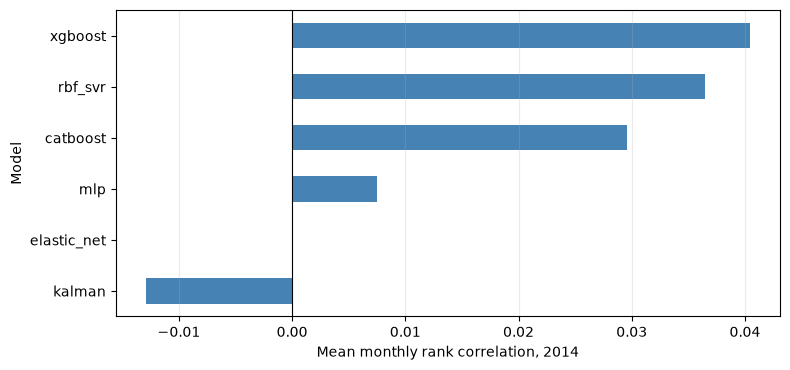

In [4]:
tuning_results = pd.read_csv(output_directory / 'tuning_summary.csv')
selection_results = pd.read_csv(output_directory / 'model_selection.csv')
display(tuning_results.merge(selection_results, on='model').sort_values(
    'rank_ic', ascending=False
))
fig, axis = plt.subplots(figsize=(8, 3.8))
selection_results.sort_values('rank_ic').plot.barh(
    x='model', y='rank_ic', ax=axis, legend=False, color='steelblue'
)
axis.axvline(0, color='black', linewidth=0.8)
axis.set(xlabel='Mean monthly rank correlation, 2014', ylabel='Model')
axis.grid(axis='x', alpha=0.25)
fig.tight_layout()
plt.show()


## Later development check and final fit

The winner is selected before inspecting its 2015 check. The final fitted
artifact uses only pre-2016 completed outcomes. Its hash and the source
configuration are recorded before the first final-test prediction. A later
poor result is retained rather than used to select another model.

The earlier 30-stock Ridge pilot already examined 2015. This later
development check is therefore not a pristine unseen holdout; the reserved
performance evaluation is the 2016–2026 final test.

This procedure limits some selection effects, but six families and 72
configurations still create multiple-testing risk. The few validation years
and overlapping 90-day labels limit how strongly the scores can be
interpreted. No independent-observation significance claim is made.


In [5]:
frozen_experiment = json.loads(
    (output_directory / 'frozen_experiment.json').read_text()
)
confirmation_metrics = json.loads(
    (output_directory / 'confirmation_metrics.json').read_text()
)
display(Markdown(f"Selected model: **{frozen_experiment['model']}**"))
display(pd.Series(frozen_experiment['parameters'], name='Selected parameters'))
display(pd.Series(confirmation_metrics, name='2015 confirmation'))
assert pd.Timestamp(
    frozen_experiment['latest_training_outcome']
) < pd.Timestamp('2016-01-01')
display(pd.Series(
    frozen_experiment['convergence_warnings'], name='Convergence warnings'
))


Selected model: **xgboost**

n_estimators        80.000000
max_depth            4.000000
learning_rate        0.129712
min_child_weight    16.957566
subsample            0.788479
colsample_bytree     0.732661
reg_lambda           1.919910
Name: Selected parameters, dtype: float64

model              xgboost
rank_ic           0.019099
rmse              0.198678
mae               0.133264
scored_rows          17915
scored_months            9
predicted_rows       21904
Name: 2015 confirmation, dtype: object

inner_2012           9
inner_2013           8
selection_2014       1
confirmation_2015    0
final                0
Name: Convergence warnings, dtype: int64

## From predictions to orders

At the close before each month's first market session, rank historically
eligible stocks and choose the top 20. Allocate an equal dollar budget per
selected name from at most 25% of NAV and available cash. Include existing
lots when enforcing a planned 5% NAV name cap. Budgets are fixed before the
next close is known, and unused capacity stays in cash. This avoids Kelly
weights that would rely on precise, unstable return estimates.

The independent backtester holds each purchase 90 calendar days, charges
10 basis points on each side, and tracks cash, lots and daily NAV. Cash earns
zero. Adjusted-price units include total-return exposure; dividends are not
added twice. Missing entry quotes cancel orders without a replacement.
Held-stock gaps are recorded, with a five-session carry limit. Longer gaps
stop the evaluation instead of inventing a price or delisting recovery.

The strategy is fixed in advance, not tuned by trying many trading variants.
The hand-checkable tests cover fees, cash budgets, next-session execution,
weekend maturity, final open positions, gaps and forbidden future columns.


In [6]:
development_status = json.loads(
    (output_directory / 'development_backtest/evaluation_status.json').read_text()
)
display(pd.Series(development_status, name='Development portfolio status'))
if development_status['status'] == 'completed':
    display(pd.read_csv(
        output_directory / 'development_backtest/performance.csv', index_col=0
    ))


status                                                                              completed
strategy                {'final_value': 868040.2896528747, 'cagr': -0.14417569617345105, '...
benchmark               {'final_value': 1031813.5305378034, 'cagr': 0.035054907627275256, ...
stale_valuation_days                                                                        0
data_incidents                                                                              0
final_open_lots                                                                            40
Name: Development portfolio status, dtype: object

,strategy,benchmark
final_value,868040.289653,1.031814e+06
cagr,-0.144176,3.505491e-02
maximum_drawdown,-0.246976,-1.203650e-01
sharpe,-0.883925,1.691796e-01


## Frozen final evaluation

Compare with the S&P 500 total-return index bought at the same first test
close. Both start with $1 million. The strategy pays the stated trading
costs; the passive benchmark is reported without fees. The comparison uses
final value including open positions, actual-time CAGR, maximum drawdown
including initial capital, and daily-return Sharpe with a 2% annual
risk-free rate. There are no model updates during this period.

The first run stopped at MYCC's cash acquisition because the database
omitted its proceeds. The corrections use verified issuer/SEC
corporate actions, without changing forecasts or model/trading parameters.
Each failed path and each corrected-run fingerprint is preserved. Cash
entitlements are valued after completion but remain restricted until the
original lot maturity. Stock conversions preserve the original holding
period. Nontrading predecessor quotes are rejected. CervoMed and Onterris
successor quotes are checked for issuer identity and overlap with the course
series; they are used only for holdings, never as model inputs.

The original stop and corrections are shown below. Partial results are
not full-period performance estimates. A completed run is conditional on the supplied
coverage, vendor restatements, capitalization-ranking anomalies, incomplete
delisting proceeds, and the adjusted-price trading abstraction.


,run,status,reason
0,final_test,unresolved_data_gap,MYCC missing 6 sessions on 2017-09-26; no verified exit or recovery.
1,final_test_corporate_actions_v1,unresolved_data_gap,VRTV missing 6 sessions on 2023-12-07; no verified exit or recovery.
2,final_test_corporate_actions_v2,unresolved_data_gap,MCW missing 6 sessions on 2026-06-01; no verified exit or recovery.
3,final_test_corporate_actions_v3,completed,Completed through test end


status                                                                              completed
strategy                {'final_value': 1312631.2851167403, 'cagr': 0.026254305431321345, ...
benchmark               {'final_value': 4402746.776270891, 'cagr': 0.1516619250925666, 'ma...
stale_valuation_days                                                                        1
data_incidents                                                                             13
final_open_lots                                                                            40
Name: Final evaluation status, dtype: object

,strategy,benchmark
final_value,1.312631e+06,4.402747e+06
cagr,2.625431e-02,1.516619e-01
maximum_drawdown,-5.371765e-01,-3.379046e-01
sharpe,1.463386e-01,7.725008e-01


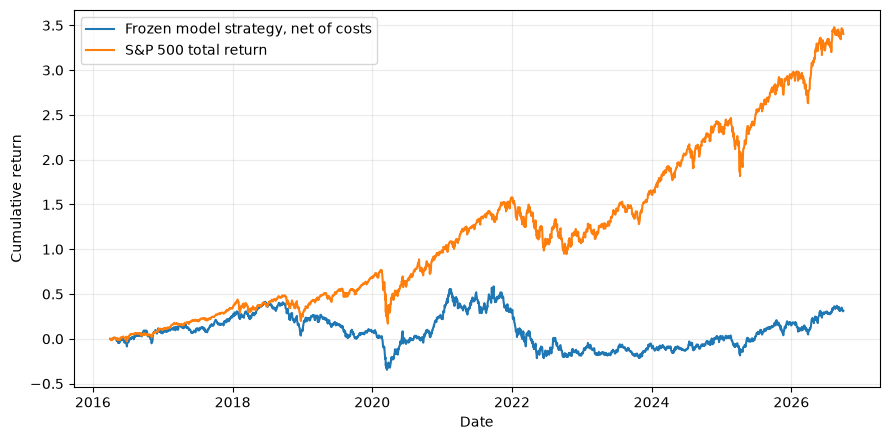

In [7]:
final_directory = output_directory / 'final_test'
correction_runs = sorted(
    output_directory.glob('final_test_corporate_actions_v*'),
    key=lambda path: int(path.name.rsplit('v', 1)[1]),
)
evaluation_log = []
for run_directory in [final_directory] + correction_runs:
    status_path = run_directory / 'evaluation_status.json'
    if status_path.exists():
        status = json.loads(status_path.read_text())
        evaluation_log.append({
            'run': run_directory.name,
            'status': status['status'],
            'reason': status.get('reason', 'Completed through test end'),
        })
if correction_runs:
    final_directory = correction_runs[-1]
display(pd.DataFrame(evaluation_log))
final_status_file = final_directory / 'evaluation_status.json'
if final_status_file.exists():
    final_status = json.loads(final_status_file.read_text())
    display(pd.Series(final_status, name='Final evaluation status'))
    if final_status['status'] == 'completed':
        display(pd.read_csv(
            final_directory / 'performance.csv', index_col=0
        ))
        if (final_directory / 'history.csv').is_file():
            strategy_history = pd.read_csv(
                final_directory / 'history.csv', parse_dates=['date']
            )
            benchmark_history = pd.read_csv(
                final_directory / 'benchmark.csv', parse_dates=['date']
            )
        else:
            saved_values = pd.read_csv(
                final_directory / 'portfolio_values.csv', parse_dates=['date']
            )
            strategy_history = saved_values.rename(
                columns={'nav_strategy': 'nav'}
            )[['date', 'nav']]
            benchmark_history = saved_values.rename(
                columns={'nav_benchmark': 'nav'}
            )[['date', 'nav']]
        fig, axis = plt.subplots(figsize=(9, 4.5))
        for label, frame in [
            ('Frozen model strategy, net of costs', strategy_history),
            ('S&P 500 total return', benchmark_history),
        ]:
            axis.plot(frame.date, frame.nav / 1_000_000 - 1, label=label)
        axis.set(xlabel='Date', ylabel='Cumulative return')
        axis.grid(alpha=0.25)
        axis.legend()
        fig.tight_layout()
        plt.show()
else:
    display(Markdown('The final evaluation has not been run.'))


## References and implementation

Data loading and causal feature construction reuse the supplied
[course_data.py](../../../Lectures/modeling/course_data.py). The backtester
in this directory is independently implemented. Boruta and Optuna are used
through their published Python packages. See the README for primary method
references and the full assumptions. Codex assisted with implementation,
tests and explanations.


## Findings

The selected XGBoost model had a 2014 monthly rank correlation of 0.0404
and a 2015 development-check correlation of 0.0191. The strategy finished
the final period at $1,312,631.29, compared with $4,402,746.78 for the
benchmark. It gained 31.26% cumulatively but trailed by 309.01 percentage
points. Its 2.63% CAGR, 53.72% drawdown and 0.146 Sharpe offer little evidence
of a robust forecasting advantage.

The limited training sample, small search budget, changing selected features,
cash exposure and source-data limitations constrain the interpretation.
The result is retained without further test-period optimization. A separate
future study could investigate a larger training sample and a simpler
momentum baseline, using a new independent evaluation period.
